In [16]:
from sklearn.datasets import load_diabetes

diabetes = load_diabetes(as_frame=True)
df = diabetes.frame

df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [17]:
print(df.shape)
print(df.isna().sum())
print(df["target"].describe())

(442, 11)
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64
count    442.000000
mean     152.133484
std       77.093005
min       25.000000
25%       87.000000
50%      140.500000
75%      211.500000
max      346.000000
Name: target, dtype: float64


In [18]:
df.dtypes

age       float64
sex       float64
bmi       float64
bp        float64
s1        float64
s2        float64
s3        float64
s4        float64
s5        float64
s6        float64
target    float64
dtype: object

In [19]:
X = df.drop(columns=["target"])
y = df["target"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.2,
    random_state=42,
    shuffle=True
)





In [20]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)

print(f"Baseline MAE {mean_absolute_error(y_test, baseline_predictions)}")
print(f"baseline RMSE: {root_mean_squared_error(y_test, baseline_predictions)}")

Baseline MAE 64.00646146990485
baseline RMSE: 73.22249283682244


In [21]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)
model_predictions = model.predict(X_test)

print(f"Model MAE {mean_absolute_error(y_test, model_predictions)}")
print(f"Model RMSE: {root_mean_squared_error(y_test, model_predictions)}")

Model MAE 42.79409467959994
Model RMSE: 53.85344583676592


Linear regression achieved a test MAE of 43.8, RMSE of 53.9, and R^2 of 0.45. It improved on the mean-prediction baseline, but substantial prediction error remains. 

In [22]:
from sklearn.metrics import r2_score

print(f"R2 score: {r2_score(y_test, model_predictions)}")

R2 score: 0.4526027629719196


In [23]:
import pandas as pd
prediction_review = pd.DataFrame({
    "actual": y_test,
    "predicted": model_predictions
})

prediction_review["residual"] = (
    prediction_review["actual"] - prediction_review["predicted"]
)

prediction_review.head()

,actual,predicted,residual
287,219.0,139.547558,79.452442
211,70.0,179.517208,-109.517208
72,202.0,134.038756,67.961244
321,230.0,291.417029,-61.417029
73,111.0,123.789659,-12.789659


In [24]:
prediction_review["absolute_error"] = (
    prediction_review["residual"].abs()
)

prediction_review.sort_values(
    "absolute_error", ascending=False
).head()


,actual,predicted,residual,absolute_error
56,52.0,206.493375,-154.493375,154.493375
77,200.0,71.666726,128.333274,128.333274
211,70.0,179.517208,-109.517208,109.517208
209,77.0,180.390940,-103.390940,103.390940
9,310.0,207.350502,102.649498,102.649498


In [28]:
print("Mean residual:", prediction_review["residual"].mean())

Mean residual: 3.912840375077804


In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.pipeline import Pipeline
help(Pipeline)

In [ ]:
from sklearn.utils import all_estimators

regressors = all_estimators(type_filter="regressor")
for name, cls in regressors:
    print(name, cls.__module__)

In [27]:
from sklearn.linear_model import LinearRegression

# dir(sklearn.linear_model)

LinearRegression()

LinearRegression()

Linear regression reduced MAE from x to y and RMSE from x to y, with a test R^2 of Z. 

limitation

These results come from one split with 89 test samples, so I'd use cross-validation to assess variability and evaluate on representative data before applying it elsewhere

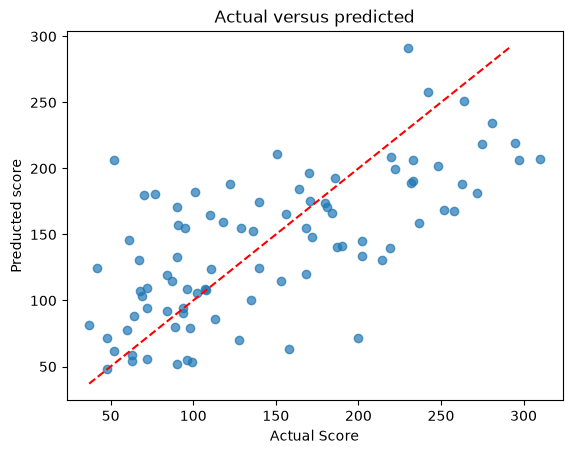

<Signature (x: 'float | ArrayLike', y: 'float | ArrayLike', s: 'float | ArrayLike | None' = None, c: 'ArrayLike | Sequence[ColorType] | ColorType | None' = None, *, marker: 'MarkerType | None' = None, cmap: 'str | Colormap | None' = None, norm: 'str | Normalize | None' = None, vmin: 'float | None' = None, vmax: 'float | None' = None, alpha: 'float | None' = None, linewidths: 'float | Sequence[float] | None' = None, edgecolors: "Literal['face', 'none'] | ColorType | Sequence[ColorType] | None" = None, colorizer: 'Colorizer | None' = None, plotnonfinite: 'bool' = False, data: 'DataParamType' = None, **kwargs) -> 'PathCollection'>

In [33]:
import matplotlib.pyplot as plt

plt.scatter(y_test, model_predictions, alpha=0.7)

low = min(y_test.min(), model_predictions.min())
high = min(y_test.max(), model_predictions.max())

plt.plot([low, high], [low, high], color="red", linestyle="--")

plt.xlabel("Actual Score")
plt.ylabel("Preducted score")
plt.title("Actual versus predicted")
plt.show()

import inspect

inspect.signature(plt.scatter)